# nb09 — MinerU для извлечения данных из PDF

**Раздел 1. Среда, установка, первый smoke-тест.**

Правила исследования:

- Только research (`ml/research/`). Прод (`ml/src/normatives_pipeline/**`), `ml/tests/**` и `.venv` не трогаем.
- Парсинг **только локальный**. `--remote` и mineru.net запрещены: нормативные PDF наружу не уходят.
- Перед замером — свежее ядро и вычищенный `__pycache__`; на кэш MinerU не полагаемся.
- Пилот — **СП 31.13330.2021**; тест — СП 22.13330.2016; невиданный — СП 24.13330.2021.


## 1.1 Среда и установка

MinerU 4.x ставится изолированно (`uv tool`), в `.venv` проекта не лезет. Верхние тиры
(`standard`/`advanced`) — это локальная мультимодальная модель (VLM), `basic` — маленькие
ONNX-модели; для research это допустимо.

In [1]:
import json, os, re, subprocess, time
from pathlib import Path

REPO = Path("/home/malkinte/CalcEngine")
PDF_SP31 = REPO / "docs" / "normative-base" / "СП 31.13330.2021.pdf"
OUT = Path("/tmp/kilo/mineru_out")
OUT.mkdir(parents=True, exist_ok=True)
BIN = Path.home() / ".local" / "bin"
ENV = {**os.environ, "PATH": f"{BIN}:{os.environ.get('PATH','')}"}


def run(*args, timeout=1800):
    t0 = time.time()
    p = subprocess.run([str(BIN / args[0]), *args[1:]], env=ENV,
                       capture_output=True, text=True, timeout=timeout)
    return p, time.time() - t0


def du(path):
    r = subprocess.run(["du", "-sh", str(path)], capture_output=True, text=True)
    return r.stdout.split()[0] if r.stdout else "?"

p, _ = run("mineru", "version")
print(p.stdout.strip())
p, _ = run("mineru-kit", "models", "verify", "--tier", "basic")
print("models basic:", (p.stdout.strip() or p.stderr.strip().splitlines()[-1]))
print("tool size:", du(Path.home() / ".local" / "share" / "uv" / "tools" / "mineru"))
print("models home:", du(Path.home() / ".mineru"))

MinerU version: 4.0.10
Python version: 3.12.3


models basic: MinerU-4_models_onnx: ok
tool size: 855M
models home: 820M


## 1.2 Smoke-парсинг пилота (tier `basic`, CPU, локально)

Stateless-режим `mineru-kit parse` не требует managed-сервера (он на этой машине не
поднялся). Замеряем время на текстовой странице и на странице с формулами.

**Важно (без кэша):** `mineru-kit parse` пропускает работу, если выходной файл уже
существует, и молча отдаёт прежний результат. Поэтому перед каждым замером выход
удаляется — иначе получаем ложные секунды.

In [2]:
def parse(pdf, out, pages, fmt, tier="basic"):
    if out.exists():          # mineru-kit пропускает парсинг, если выход уже есть: кэш не используем
        out.unlink()
    p, dt = run("mineru-kit", "parse", str(pdf), "-o", str(out),
                "-p", pages, "--tier", tier, "-f", fmt)
    ok = out.exists()
    print(f"{out.name}: ok={ok} fmt={fmt} pages={pages} time={dt:.1f}s")
    if not ok:
        print(p.stderr[-600:])
    return dt

t_text = parse(PDF_SP31, OUT / "sp31_p1-2.json", "1-2", "middle_json")
t_form = parse(PDF_SP31, OUT / "sp31_p54-64.md", "54,64", "markdown")
print(f"speed: text ~{2 / t_text:.2f} стр/с | формулы ~{2 / t_form:.2f} стр/с")

sp31_p1-2.json: ok=True fmt=middle_json pages=1-2 time=10.3s


sp31_p54-64.md: ok=True fmt=markdown pages=54,64 time=28.1s
speed: text ~0.19 стр/с | формулы ~0.07 стр/с


## 1.3 Структура вывода (`middle_json`): блоки, bbox, типы

Проверяем, что MinerU даёт не плоский текст, а размеченные блоки с координатами.

In [3]:
data = json.loads((OUT / "sp31_p1-2.json").read_text())
print("schema:", data["schema"], data["schema_version"])
ext = data["extensions"]["mineru"]
print("tier:", ext["tier"], "| parse_mode:", ext["parse_mode"])
for pg in data["pages"]:
    types = [b["type"] for b in pg["blocks"]]
    print(f"page {pg['page_idx']}: {len(types)} блоков -> {types}")
b0 = data["pages"][0]["blocks"][0]
print("пример блока:", {k: b0[k] for k in ("type", "bbox", "level") if k in b0})
c0 = b0["content"][0]
print("текст:", c0["content"][:70], "| styles:", c0.get("styles"))

schema: docvortex.middle 2.0
tier: basic | parse_mode: txt
page 0: 7 блоков -> ['doc_title', 'text', 'text', 'doc_title', 'text', 'text', 'text']
page 1: 12 блоков -> ['header', 'paragraph_title', 'paragraph_title', 'text', 'text', 'text', 'text', 'text', 'text', 'footer', 'footer', 'page_number']
пример блока: {'type': 'doc_title', 'bbox': [0.25, 0.069, 0.819, 0.133], 'level': 1}
текст: МИНИСТЕРСТВО СТРОИТЕЛЬСТВА И ЖИЛИЩНО-КОММУНАЛЬНОГО ХОЗЯЙСТВА РОССИЙСКО | styles: None


## 1.4 Формулы и таблицы в Markdown-выводе

Ключевое: формула распознаётся (`MFR Predict`) и получает номер в `\tag{}`; таблица —
как HTML `<table>`. Смотрим, что реально получилось на пилоте.

In [4]:
md = (OUT / "sp31_p54-64.md").read_text()
tags = re.findall(r"\\tag\{([^}]*)\}", md)
print("формул с \\tag:", len(tags), tags)
print("HTML-таблиц:", md.count("<table>"),
      "| подписей 'Т а б л и ц а':", len(re.findall(r"Т а б л и ц а", md)))
print("заголовки (##):", re.findall(r"^## .*", md, re.M))
print("--- строки с формулами ---")
for i, line in enumerate(md.splitlines(), 1):
    s = line.strip()
    if "\\tag{" in s or s.startswith("$$") or "<table>" in s:
        print(i, s[:150])

формул с \tag: 3 ['10', '10', '11']
HTML-таблиц: 1 | подписей 'Т а б л и ц а': 1
заголовки (##): ['## Контактные осветлители', '## Фторирование воды']
--- строки с формулами ---
3 $$
4 H_{\mathrm{w}} = H_{3} a_{3} / 100 + 0.3,\tag{10}
5 $$
51 $$
52 \Pi_{\mathrm{x}}=0,7(\mathrm{Fe}^{2+});\tag{10}
53 $$
57 $$
58 \begin{array} { r } { \underline { { \boldsymbol { \Pi } } } _ { \mathrm { \Pi } } = ( \mathrm { F } \mathbf { e } ^ { 2 + } ) . } \end{array}\tag{11}
59 $$
67 <table><tbody><tr><td colspan="5">Характеристика фильтрующего слоя при обезжелезивании водыупрощенной аэрацией</td><td rowspan="2">Расчетнаяскоростьфи


## 1.5 Визуальная сверка PDF ↔ вывод (стр. 54, п. 9.88)

Правило проекта: для каждой значимой находки — кроп страницы PDF рядом с тем, что даёт
инструмент.

**PDF СП 31, стр. 54 (верхняя половина, п. 9.88):**

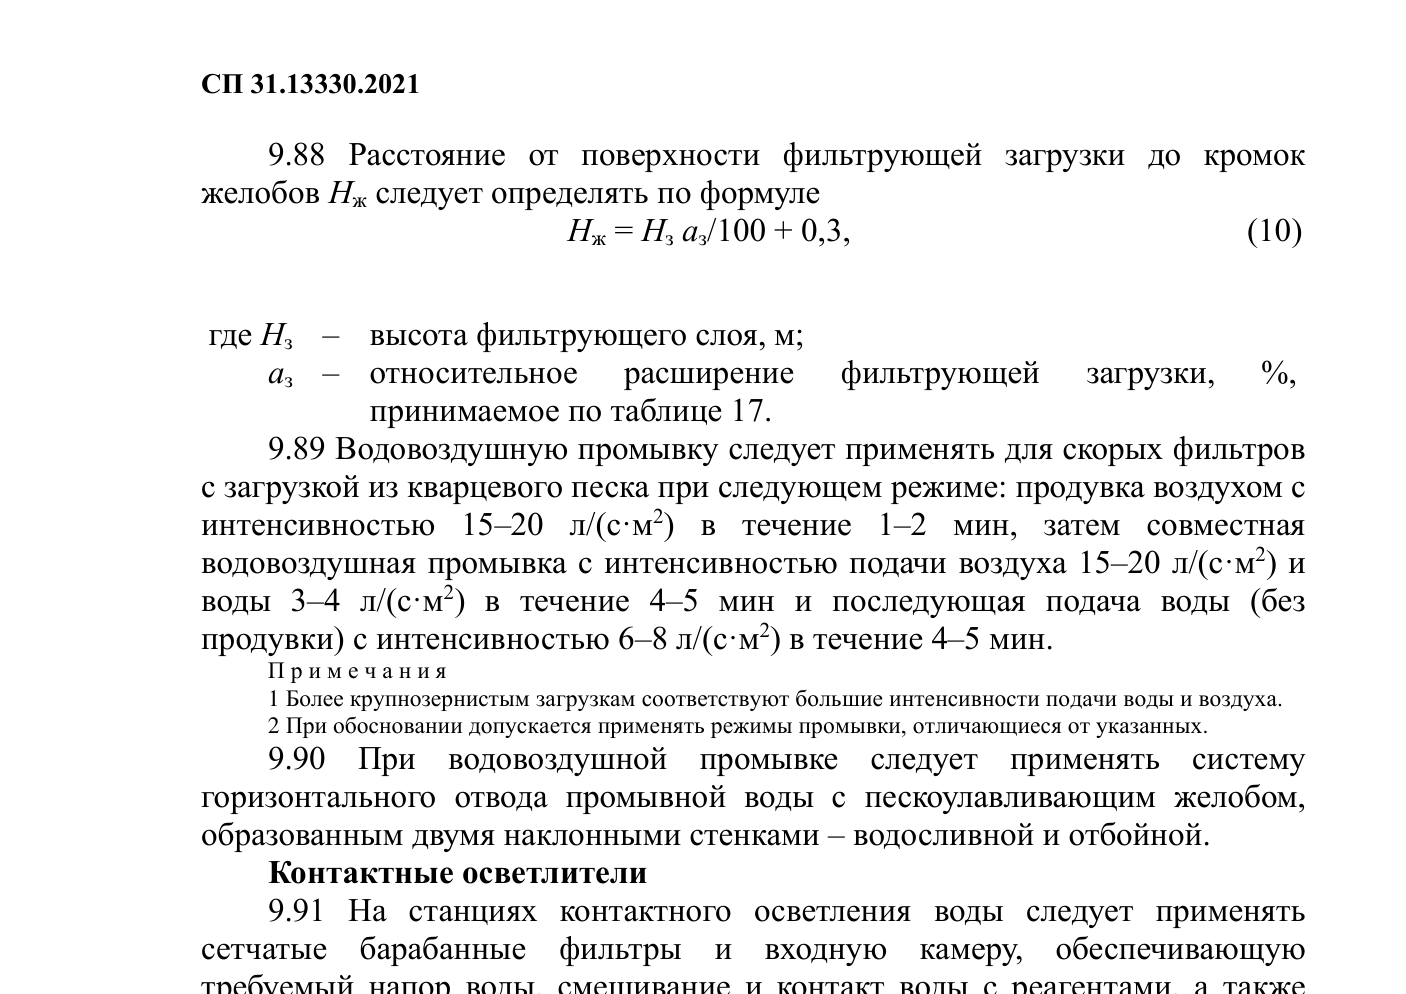

**MinerU `basic`, распознанная формула 9.88:**

H_{\mathrm{w}} = H_{3} a_{3} / 100 + 0.3,\tag{10}


In [5]:
import pymupdf
from IPython.display import Image, display, Markdown

doc = pymupdf.open(PDF_SP31)
pg = doc[53]
clip = pymupdf.Rect(0, 0, pg.rect.width, pg.rect.height * 0.5)
crop = OUT / "sp31_p54_formula.png"
pg.get_pixmap(clip=clip, dpi=170).save(crop)
display(Markdown("**PDF СП 31, стр. 54 (верхняя половина, п. 9.88):**"))
display(Image(filename=str(crop), width=560))
m = re.search(r"\$\$(.*?)\$\$", md, re.S)
display(Markdown("**MinerU `basic`, распознанная формула 9.88:**"))
print(m.group(1).strip() if m else "не найдено")

## 1.6 Выводы раздела 1

Промежуточные (по фактическому прогону выше):

1. **Ставится и работает локально** без сервера: `mineru-kit parse` (stateless), tier `basic`, CPU.
2. **Layout богаче плоского текста**: типы блоков (`doc_title`, `paragraph_title`, `text`,
   `header`, `footer`, `page_number`), нормализованный `bbox`, стили `bold`; заголовки
   разделов распознаются как `##`.
3. **Номера формул сохраняются** в `\tag{...}`, в т.ч. дубль `(10)` в п. 9.88 и п. 9.145 —
   важно для проблемы дублирующихся номеров.
4. **Таблицы** отдаются как HTML `<table>` с ячейками и подписью отдельным блоком.
5. **Главный минус:** кириллица внутри формул деградирует так же, как в нашем текстовом слое
   (`H_з → H_{3}`, `a_з → a_{3}`, `Д → \Pi`), часть формул зашумлена (п. 9.145, формула (11)).
   В ячейках таблиц теряются пробелы.

**Что проверяем дальше:** сравнить `basic` с `standard` (VLM) на тех же страницах — гипотеза,
что VLM лучше держит кириллические индексы и сложную вёрстку. Отдельно — количественно
сопоставить с текущим детерминированным пайплайном.
